# 1500 MW over 140 mi at 345 kV — losses and compensation (pandapower)

**Task.** Deliver $P_R = 1500\,\mathrm{MW}$ at the receiving end of a 140 mi, 345 kV AC overhead line with a 3-conductor Bluebird ACSR bundle per phase. Determine the transmission losses and the compensation the line needs.

**Approach.** Each case is a small pandapower network: an external grid (slack, 1.0 p.u.) at the sending end S, the load at the receiving end R, the line as a π-equivalent with the constants derived from the conductor and tower geometry. Compensation is modelled as

- a *voltage-controlled reactive source* at R (`gen` with $P = 0$, $U_R = 1.0$ p.u.) — its resulting $Q$ is the shunt compensation the line needs (SVC / STATCOM / switched capacitor banks, or the reactive capability of a VSC converter station);
- a *midpoint series capacitor* as a pandapower `impedance` element with negative reactance, $X_C = k\cdot X_L$;
- parallel circuits via the line's `parallel` attribute (identical towers side by side).

Cases: single circuit uncompensated, with shunt compensation, with series + shunt compensation; two and three parallel circuits; and the same conductor at 500 kV for comparison. A no-load case gives the shunt-reactor requirement at light load.


In [1]:
import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 1)

MI_TO_KM, FT_TO_M, IN_TO_M = 1.609344, 0.3048, 0.0254


## 1. Line data

Flat single-circuit 345 kV configuration. The 26 ft phase spacing is a typical value for 345 kV flat towers — adjust to the actual tower. Conductor data from the Southwire ACSR tables (Bluebird 2156 kcmil 84/19), resistance at 75 °C.


In [2]:
U_n   = 345.0            # kV
f     = 60.0             # Hz
omega = 2*np.pi*f
L_mi  = 140.0
L_km  = L_mi*MI_TO_KM
P_R   = 1500.0           # MW delivered at the receiving end
pf_R  = 1.00             # power factor of the delivered power (1.0: converter station / compensated load)

# Bluebird ACSR 2156 kcmil 84/19 (Southwire 11-4)
r_ac_75_per_kft = 0.0520   # Ohm / 1000 ft at 75 C
d_cond_in       = 1.762
GMR_cond_ft     = 0.0588
I_cond_kA       = 1.30     # approx. ampacity per subconductor at 75 C

n_sub    = 3
s_bundle = 18*IN_TO_M
D_ph     = 26*FT_TO_M      # flat, adjacent phase spacing

r_cond, GMR_cond = d_cond_in*IN_TO_M/2, GMR_cond_ft*FT_TO_M
GMR_b = (GMR_cond*s_bundle**2)**(1/3)
r_b   = (r_cond*s_bundle**2)**(1/3)
GMD   = (D_ph*D_ph*2*D_ph)**(1/3)
mu0, eps0 = 4e-7*np.pi, 8.854e-12

R_km = r_ac_75_per_kft/(1000*FT_TO_M)/n_sub*1e3            # Ohm/km
L_km_H = mu0/(2*np.pi)*np.log(GMD/GMR_b)*1e3                # H/km
C_km_F = 2*np.pi*eps0/np.log(GMD/r_b)*1e3                   # F/km
X_km  = omega*L_km_H
C_nF  = C_km_F*1e9
Z_w   = np.sqrt(L_km_H/C_km_F)
P_nat = U_n**2/Z_w
I_th  = n_sub*I_cond_kA

print(f"R' = {R_km:.4f} Ohm/km   X' = {X_km:.4f} Ohm/km   C' = {C_nF:.1f} nF/km")
print(f"Line totals: R = {R_km*L_km:.1f} Ohm, X_L = {X_km*L_km:.1f} Ohm, charging {omega*C_km_F*L_km*U_n**2:.0f} Mvar")
print(f"Z_w = {Z_w:.0f} Ohm  ->  P_nat = {P_nat:.0f} MW;  thermal rating {np.sqrt(3)*U_n*I_th:.0f} MVA per circuit ({I_th:.1f} kA)")
print(f"Requested transfer: {P_R:.0f} MW = {P_R/P_nat:.2f} x P_nat   -> I = {P_R/(np.sqrt(3)*U_n):.2f} kA per circuit if on one circuit")


R' = 0.0569 Ohm/km   X' = 0.3139 Ohm/km   C' = 13.6 nF/km
Line totals: R = 12.8 Ohm, X_L = 70.7 Ohm, charging 138 Mvar
Z_w = 247 Ohm  ->  P_nat = 481 MW;  thermal rating 2330 MVA per circuit (3.9 kA)
Requested transfer: 1500 MW = 3.12 x P_nat   -> I = 2.51 kA per circuit if on one circuit


The requested transfer is about $3\cdot P_{nat}$ on a 225 km line — far above the natural loading, so the line will be heavily inductive: large reactive consumption ($3\cdot I^2\cdot X_L$), a big transmission angle and, since $I \approx 2.5$ kA, substantial $I^2 R$ losses on a single circuit.

## 2. Network builder


In [3]:
def build_net(P_mw=P_R, pf=pf_R, U_kv=U_n, parallel=1, k=0.0, hold_UR=None, length_km=L_km):
    '''S --(line, optionally split around a midpoint series capacitor)-- R with load.
       hold_UR: if set, a P=0 gen at R regulates |U_R| to this value; its Q is the shunt compensation.'''
    net = pp.create_empty_network(sn_mva=100.0, f_hz=f)
    bS = pp.create_bus(net, U_kv, name="S")
    bR = pp.create_bus(net, U_kv, name="R")
    pp.create_ext_grid(net, bS, vm_pu=1.0, name="sending system")
    Q_mvar = P_mw*np.tan(np.arccos(pf))
    pp.create_load(net, bR, p_mw=P_mw, q_mvar=Q_mvar, name="receiving end")
    line_kw = dict(r_ohm_per_km=R_km, x_ohm_per_km=X_km, c_nf_per_km=C_nF,
                   max_i_ka=I_th, parallel=parallel)
    if k > 0:
        bM1 = pp.create_bus(net, U_kv, name="bank in"); bM2 = pp.create_bus(net, U_kv, name="bank out")
        pp.create_line_from_parameters(net, bS, bM1, length_km/2, name="line S-half", **line_kw)
        X_C = k*X_km*length_km/parallel            # Ohm, equivalent of one bank per circuit
        z_base = U_kv**2/net.sn_mva
        pp.create_impedance(net, bM1, bM2, rft_pu=1e-6, xft_pu=-X_C/z_base, sn_mva=net.sn_mva, name="series capacitor")
        pp.create_line_from_parameters(net, bM2, bR, length_km/2, name="line R-half", **line_kw)
    else:
        pp.create_line_from_parameters(net, bS, bR, length_km, name="line", **line_kw)
    if hold_UR is not None:
        pp.create_gen(net, bR, p_mw=0.0, vm_pu=hold_UR, min_q_mvar=-5000, max_q_mvar=5000, name="shunt compensation")
    return net

def solve(net):
    try:
        pp.runpp(net, init="flat", max_iteration=60, numba=False)
        return True
    except pp.LoadflowNotConverged:
        return False

def summary(net, label):
    bS, bR = 0, 1
    ok = solve(net)
    if not ok:
        return dict(case=label, converged=False)
    P_loss = net.res_line.pl_mw.sum()
    out = dict(case=label, converged=True,
               P_S_MW=net.res_ext_grid.p_mw[0], Q_S_Mvar=net.res_ext_grid.q_mvar[0],
               P_loss_MW=P_loss, loss_pct=100*P_loss/net.load.p_mw.sum(),
               U_R_pu=net.res_bus.vm_pu[bR],
               delta_deg=net.res_bus.va_degree[bS]-net.res_bus.va_degree[bR],
               Q_comp_Mvar=net.res_gen.q_mvar.sum() if len(net.gen) else 0.0,
               I_max_kA=net.res_line.i_ka.max()/net.line.parallel.max(),
               loading_pct=net.res_line.loading_percent.max())
    return out

results = []


## 3. Case A — single circuit, no compensation

With a unity-pf load and no voltage support at R, the load flow does not converge at 1500 MW: the operating point lies beyond the nose of the P–U curve. A power sweep shows how much a single uncompensated circuit can actually deliver.


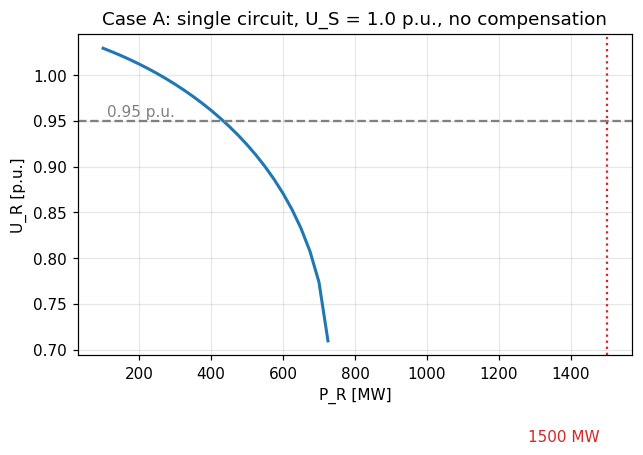

Last converged point: 725 MW;  U_R >= 0.95 p.u. up to 425 MW


In [4]:
P_sweep = np.arange(100, 1600, 25)
U_R, loss = [], []
for P in P_sweep:
    net = build_net(P_mw=P)
    if solve(net):
        U_R.append(net.res_bus.vm_pu[1]); loss.append(net.res_line.pl_mw.sum())
    else:
        U_R.append(np.nan); loss.append(np.nan)
U_R, loss = np.array(U_R), np.array(loss)
P_max_A = P_sweep[~np.isnan(U_R)].max()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(P_sweep, U_R, lw=2)
ax.axhline(0.95, ls="--", color="gray"); ax.text(110, 0.955, "0.95 p.u.", color="gray")
ax.axvline(P_R, ls=":", color="tab:red"); ax.text(P_R-20, 0.6, "1500 MW", color="tab:red", ha="right")
ax.set_xlabel("P_R [MW]"); ax.set_ylabel("U_R [p.u.]"); ax.set_title("Case A: single circuit, U_S = 1.0 p.u., no compensation")
plt.show()

i95 = np.nanargmax(np.where(U_R >= 0.95, P_sweep, np.nan))
print(f"Last converged point: {P_max_A:.0f} MW;  U_R >= 0.95 p.u. up to {P_sweep[i95]:.0f} MW")
results.append(dict(case="A  1 circuit, no compensation", converged=False))


## 4. Cases B, C — single circuit with compensation

B: shunt compensation at R holds $U_R = 1.0$ p.u. C: additionally a midpoint series capacitor bank with $k = 0.5$.


In [5]:
results.append(summary(build_net(hold_UR=1.0),        "B  1 circuit, shunt comp. at R"))
results.append(summary(build_net(hold_UR=1.0, k=0.5), "C  1 circuit, k = 0.5 series + shunt"))
pd.DataFrame(results).set_index("case")


,converged,P_S_MW,Q_S_Mvar,P_loss_MW,loss_pct,U_R_pu,delta_deg,Q_comp_Mvar,I_max_kA,loading_pct
case,,,,,,,,,,
"A 1 circuit, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"B 1 circuit, shunt comp. at R",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"C 1 circuit, k = 0.5 series + shunt",True,1875.6,-150.2,375.6,25.0,1.0,34.5,1059.7,3.1,80.7


Case B does not converge either: with $|U_S| = |U_R| = 1.0$ p.u. the uncompensated circuit's static limit is $P_{max} \approx U^2/X_L \approx 1680$ MW *at the sending end*, and 1500 MW delivered plus the losses exceeds it — the shunt device alone cannot make the single circuit work. With the $k = 0.5$ series bank (case C) the transfer is feasible, but the circuit loses about a quarter of the delivered power: the current is above 3 kA, so $3\cdot I^2\cdot R$ with $R = 12.8\,\Omega$ runs to several hundred MW and the losses themselves add to the current. The series bank acts on $X$, not on $R$. A single 345 kV circuit is not a viable design; case C is also what the double-circuit line looks like with one circuit out (n−1).

## 5. Cases D, E, F — parallel circuits

Two or three identical circuits share the current; losses fall roughly with $1/n$.


In [6]:
results.append(summary(build_net(parallel=2, hold_UR=1.0),        "D  2 circuits, shunt comp. at R"))
results.append(summary(build_net(parallel=2, hold_UR=1.0, k=0.4), "E  2 circuits, k = 0.4 series + shunt"))
results.append(summary(build_net(parallel=2),                     "E0 2 circuits, no compensation"))
results.append(summary(build_net(parallel=3, hold_UR=1.0),        "F  3 circuits, shunt comp. at R"))
pd.DataFrame(results).set_index("case")


,converged,P_S_MW,Q_S_Mvar,P_loss_MW,loss_pct,U_R_pu,delta_deg,Q_comp_Mvar,I_max_kA,loading_pct
case,,,,,,,,,,
"A 1 circuit, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"B 1 circuit, shunt comp. at R",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"C 1 circuit, k = 0.5 series + shunt",True,1875.6,-150.2,375.6,25.0,1.0,34.5,1059.7,3.1,80.7
"D 2 circuits, shunt comp. at R",True,1646.7,-17.6,146.7,9.8,1.0,28.9,552.5,1.4,35.3
"E 2 circuits, k = 0.4 series + shunt",True,1647.2,-363.4,147.2,9.8,1.0,17.7,578.1,1.4,36.2
"E0 2 circuits, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"F 3 circuits, shunt comp. at R",True,1590.8,-235.5,90.8,6.1,1.0,18.4,324.4,0.9,23.0


## 6. Case G — same conductor at 500 kV

The alternative to more circuits is a higher voltage. With the same 3×Bluebird bundle (and a 35 ft flat spacing) at 500 kV the current for 1500 MW drops to 1.73 kA.


In [7]:
D_ph_500 = 35*FT_TO_M
GMD_500  = (D_ph_500*D_ph_500*2*D_ph_500)**(1/3)
X_km_500 = omega*mu0/(2*np.pi)*np.log(GMD_500/GMR_b)*1e3
C_nF_500 = 2*np.pi*eps0/np.log(GMD_500/r_b)*1e3*1e9

def build_net_500(parallel=1, hold_UR=None, k=0.0):
    global X_km, C_nF
    X_sav, C_sav = X_km, C_nF
    X_km, C_nF = X_km_500, C_nF_500
    net = build_net(U_kv=500.0, parallel=parallel, hold_UR=hold_UR, k=k)
    X_km, C_nF = X_sav, C_sav
    return net

results.append(summary(build_net_500(parallel=1),              "G0 500 kV, 1 circuit, no compensation"))
results.append(summary(build_net_500(parallel=1, hold_UR=1.0), "G  500 kV, 1 circuit, shunt comp. at R"))
results.append(summary(build_net_500(parallel=2, hold_UR=1.0), "G2 500 kV, 2 circuits, shunt comp. at R"))
df = pd.DataFrame(results).set_index("case")
df


,converged,P_S_MW,Q_S_Mvar,P_loss_MW,loss_pct,U_R_pu,delta_deg,Q_comp_Mvar,I_max_kA,loading_pct
case,,,,,,,,,,
"A 1 circuit, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"B 1 circuit, shunt comp. at R",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"C 1 circuit, k = 0.5 series + shunt",True,1875.6,-150.2,375.6,25.0,1.0,34.5,1059.7,3.1,80.7
"D 2 circuits, shunt comp. at R",True,1646.7,-17.6,146.7,9.8,1.0,28.9,552.5,1.4,35.3
"E 2 circuits, k = 0.4 series + shunt",True,1647.2,-363.4,147.2,9.8,1.0,17.7,578.1,1.4,36.2
"E0 2 circuits, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"F 3 circuits, shunt comp. at R",True,1590.8,-235.5,90.8,6.1,1.0,18.4,324.4,0.9,23.0
"G0 500 kV, 1 circuit, no compensation",False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"G 500 kV, 1 circuit, shunt comp. at R",True,1638.7,10.1,138.7,9.2,1.0,29.3,540.9,1.9,48.5


## 7. Light load — shunt reactors

At no load the charging current raises the receiving-end voltage (Ferranti effect). The required shunt reactor at R to bring the open-ended line back to 1.0 p.u. is found the same way, with the voltage-controlled element absorbing reactive power.


In [8]:
rows = []
for n_par in (1, 2, 3):
    net = build_net(P_mw=0.0, parallel=n_par); solve(net)
    u_open = net.res_bus.vm_pu[1]
    net = build_net(P_mw=0.0, parallel=n_par, hold_UR=1.0); solve(net)
    rows.append(dict(circuits=n_par, U_R_open_pu=u_open, Q_reactor_Mvar=-net.res_gen.q_mvar.sum(),
                     Q_charging_total_Mvar=omega*C_km_F*L_km*U_n**2*n_par))
with pd.option_context("display.precision", 3):
    display(pd.DataFrame(rows).set_index("circuits"))


,U_R_open_pu,Q_reactor_Mvar,Q_charging_total_Mvar
circuits,,,
1,1.043,68.767,137.534
2,1.043,137.534,275.067
3,1.043,206.301,412.601


The open-end voltage rise is modest at 140 mi ($\beta\cdot l \approx 16^\circ$), but each circuit still generates about 140 Mvar of charging power; the reactive compensation at R therefore has to be *bidirectional* — absorbing ≈ 70 Mvar per circuit at no load and supplying several hundred Mvar at 1500 MW. That points to an SVC/STATCOM, or to the reactive capability of a VSC converter station if the receiving end is an HVDC terminal.

## 8. Summary


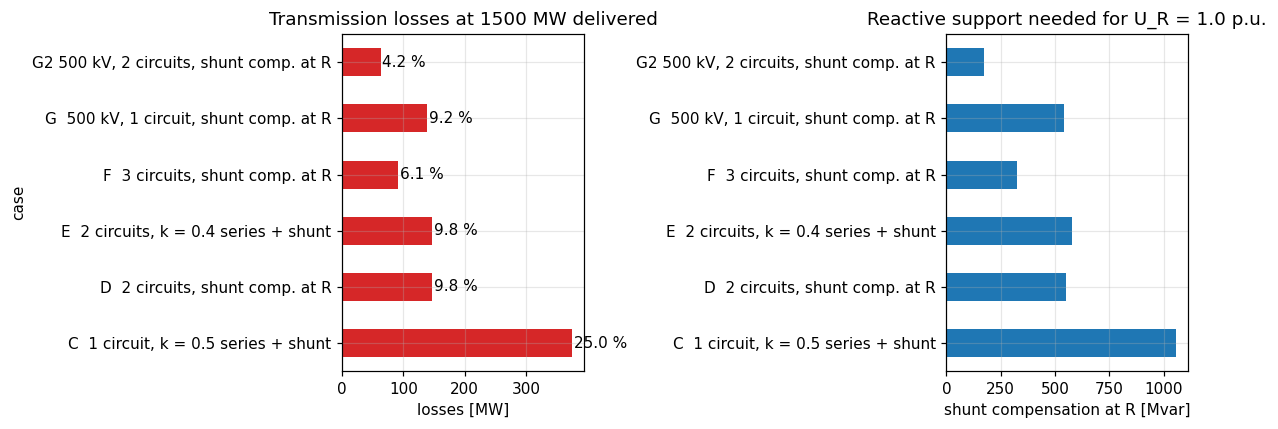

,P_loss_MW,loss_pct,Q_comp_Mvar,delta_deg,I_max_kA,loading_pct,converged
case,,,,,,,
"A 1 circuit, no compensation",NaN,NaN,NaN,NaN,NaN,NaN,False
"B 1 circuit, shunt comp. at R",NaN,NaN,NaN,NaN,NaN,NaN,False
"C 1 circuit, k = 0.5 series + shunt",375.6,25.0,1059.7,34.5,3.1,80.7,True
"D 2 circuits, shunt comp. at R",146.7,9.8,552.5,28.9,1.4,35.3,True
"E 2 circuits, k = 0.4 series + shunt",147.2,9.8,578.1,17.7,1.4,36.2,True
"E0 2 circuits, no compensation",NaN,NaN,NaN,NaN,NaN,NaN,False
"F 3 circuits, shunt comp. at R",90.8,6.1,324.4,18.4,0.9,23.0,True
"G0 500 kV, 1 circuit, no compensation",NaN,NaN,NaN,NaN,NaN,NaN,False
"G 500 kV, 1 circuit, shunt comp. at R",138.7,9.2,540.9,29.3,1.9,48.5,True


In [9]:
ok = df[df.converged == True]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ok.P_loss_MW.plot.barh(ax=axes[0], color="tab:red"); axes[0].set_xlabel("losses [MW]"); axes[0].set_title("Transmission losses at 1500 MW delivered")
for i, v in enumerate(ok.loss_pct): axes[0].text(ok.P_loss_MW.iloc[i]+3, i, f"{v:.1f} %", va="center")
ok.Q_comp_Mvar.plot.barh(ax=axes[1], color="tab:blue"); axes[1].set_xlabel("shunt compensation at R [Mvar]"); axes[1].set_title("Reactive support needed for U_R = 1.0 p.u.")
axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

df[["P_loss_MW", "loss_pct", "Q_comp_Mvar", "delta_deg", "I_max_kA", "loading_pct", "converged"]]


### Conclusions

1. **A single 345 kV circuit cannot do the job.** Uncompensated it delivers at most ≈ 725 MW (case A, 425 MW within the 0.95 p.u. band); shunt support alone is not enough (case B); only with 50 % series compensation does it reach 1500 MW, at roughly 25 % losses and more than 3 kA — within the conductor rating, economically absurd.
2. **Losses are an $I^2 R$ problem, not a reactive one.** Series compensation reduces the transmission angle and the stability margin problem (C vs B, E vs D) but leaves the losses essentially unchanged. Only more copper in parallel or a higher voltage reduces them: two circuits ≈ 10 % (147 MW), three circuits ≈ 6 % (91 MW), 500 kV single circuit ≈ 9 % (139 MW), 500 kV double circuit ≈ 4 % (63 MW).
3. **Compensation required at 345 kV, two circuits:** about 550 Mvar of capacitive support at the receiving end at full load, swinging to ≈ 140 Mvar inductive at no load; a midpoint series bank ($k \approx 0.4$, $X_C \approx 28\,\Omega$, ≈ 2 × 170 Mvar) is advisable for the angle and for (n−1) operation on one circuit, where the angle and the reactive demand roughly double. If the receiving end is a VSC converter, its reactive capability can replace the shunt device.
4. **Recommendation:** compare "2 × 345 kV + series/shunt compensation" against "1 × 500 kV + shunt compensation" on a lifetime-loss basis: the 500 kV single circuit has the same losses as the 345 kV double circuit with one tower line and one right-of-way.

*Checks worth adding:* load power factor other than 1.0, conductor temperature/ampacity for the actual ambient, and SSR screening for the series bank.
